In [12]:

# Install the required libraries
!pip -q install pandas numpy scikit-learn lightgbm matplotlib joblib requests tqdm

# Import the libraries
import os
import json
import time
import random
import subprocess
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep all experiment settings in one place
CONFIG = {
    "seed": 42,
    "sample_size": 100_000,
    "min_duration_seconds": 60,
    "max_duration_seconds": 10_800,
    "nyc_min_lat": 40.45,
    "nyc_max_lat": 41.00,
    "nyc_min_lon": -74.30,
    "nyc_max_lon": -73.65,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_estimators": 1000,
    "early_stopping_rounds": 50,
    "osrm_workers": 4,
    "osrm_url": "http://127.0.0.1:5000",
    "data_dir": "/content/quickpull",
}

# Make random sampling and splitting reproducible
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

# Create a folder for our project files
os.makedirs(CONFIG["data_dir"], exist_ok=True)

print("Setup completed successfully!")
print("LightGBM version:", lgb.__version__)
print("Project folder:", CONFIG["data_dir"])
print("Maximum sample size:", CONFIG["sample_size"])


Setup completed successfully!
LightGBM version: 4.6.0
Project folder: /content/quickpull
Maximum sample size: 100000


In [1]:

# Check whether Google Colab has assigned a GPU
import subprocess

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("GPU is available:")
    print(result.stdout)
else:
    print("No GPU detected. We can continue using the CPU.")


GPU is available:
Sun Oct 11 11:40:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------

In [13]:

# Install the libraries required for our ETA prediction project
!pip -q install lightgbm kaggle requests matplotlib pandas scikit-learn

In [3]:

# Upload the three dataset files from your computer
from google.colab import files

uploaded = files.upload()


Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [14]:

# Check whether all three dataset files are available
import os

required_files = [
    "train.csv",
    "test.csv",
    "sample_submission.csv"
]

for file in required_files:
    if os.path.exists(file):
        print(f"{file} - Found")
    else:
        print(f"{file} - Missing")


train.csv - Found
test.csv - Found
sample_submission.csv - Found


In [15]:

# Load the training dataset and inspect its structure
import pandas as pd

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (1458644, 11)

Column names:
['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']

First five rows:


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [16]:

# Select a reproducible sample of 100,000 trips
df_sample = df.sample(n=100_000, random_state=42).copy()

print("Sample shape:", df_sample.shape)
print("\nMissing values in each column:")
print(df_sample.isnull().sum())

print("\nTrip duration summary (seconds):")
print(df_sample["trip_duration"].describe())


Sample shape: (100000, 11)

Missing values in each column:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

Trip duration summary (seconds):
count    100000.000000
mean        971.345080
std        3395.006506
min           2.000000
25%         395.000000
50%         661.000000
75%        1078.000000
max       86366.000000
Name: trip_duration, dtype: float64


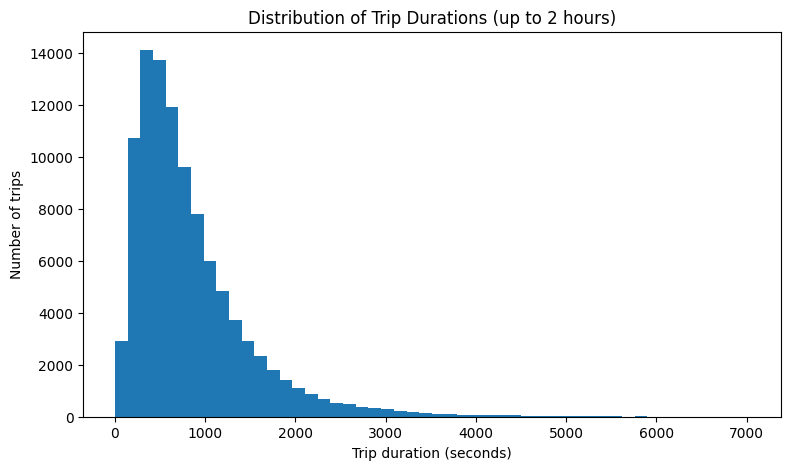

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,-73.973384,40.750817,-73.973464,40.751675
std,0.041252,0.034423,0.043186,0.038512
min,-77.896019,35.310307,-79.817978,35.173546
25%,-73.991943,40.737311,-73.991364,40.735774
50%,-73.981750,40.754019,-73.979736,40.754452
75%,-73.967255,40.768429,-73.962997,40.769837
max,-72.074333,41.033432,-72.022408,41.201595


In [17]:

# Inspect trip durations and geographic coordinates
import matplotlib.pyplot as plt

# Plot trip durations up to 2 hours for better visibility
plt.figure(figsize=(9, 5))
plt.hist(
    df_sample.loc[df_sample["trip_duration"] <= 7200, "trip_duration"],
    bins=50
)
plt.xlabel("Trip duration (seconds)")
plt.ylabel("Number of trips")
plt.title("Distribution of Trip Durations (up to 2 hours)")
plt.show()

# Check the minimum and maximum coordinates
coordinate_columns = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude"
]

display(df_sample[coordinate_columns].describe())


In [18]:
# Keep trips inside the NYC area and with plausible durations,
# using the limits stored in CONFIG (60 seconds to 3 hours)

df_clean = df_sample[
    df_sample["pickup_longitude"].between(CONFIG["nyc_min_lon"], CONFIG["nyc_max_lon"]) &
    df_sample["dropoff_longitude"].between(CONFIG["nyc_min_lon"], CONFIG["nyc_max_lon"]) &
    df_sample["pickup_latitude"].between(CONFIG["nyc_min_lat"], CONFIG["nyc_max_lat"]) &
    df_sample["dropoff_latitude"].between(CONFIG["nyc_min_lat"], CONFIG["nyc_max_lat"]) &
    df_sample["trip_duration"].between(CONFIG["min_duration_seconds"], CONFIG["max_duration_seconds"])
].copy()

print("Original sample size:", len(df_sample))
print("Cleaned sample size :", len(df_clean))
print("Removed trips       :", len(df_sample) - len(df_clean))
print("\nTrip duration summary (seconds):")
print(df_clean["trip_duration"].describe())

Original sample size: 100000
Cleaned sample size : 99177
Removed trips       : 823

Trip duration summary (seconds):
count    99177.000000
mean       841.301088
std        655.756255
min         60.000000
25%        400.000000
50%        664.000000
75%       1078.000000
max       9155.000000
Name: trip_duration, dtype: float64


In [19]:
# Split the cleaned data: 70% train, 15% validation, 15% test
from sklearn.model_selection import train_test_split

# Step 1: keep 70% for training, put the other 30% aside
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=CONFIG["seed"]
)

# Step 2: split that 30% into two equal halves (15% validation, 15% test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=CONFIG["seed"]
)

# Reset row numbers so each set starts from 0
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Show the size and share of each set
total = len(df_clean)
for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:<11}: {len(part):>7,} trips ({len(part)/total:.1%})")

# Quick check that the sets have similar duration statistics
print("\nMedian trip duration (seconds):")
print("Train     :", train_df["trip_duration"].median())
print("Validation:", val_df["trip_duration"].median())
print("Test      :", test_df["trip_duration"].median())

# Reminder: the test set is NOT touched again until the very end

Train      :  69,423 trips (70.0%)
Validation :  14,877 trips (15.0%)
Test       :  14,877 trips (15.0%)

Median trip duration (seconds):
Train     : 664.0
Validation: 661.0
Test      : 663.0


In [20]:
# Check the Colab machine before we try to install OSRM
import shutil, os, subprocess

# Run a shell command and print its output
def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print((r.stdout + r.stderr).strip())

print("=== Ubuntu version ===")
run("lsb_release -ds")

print("\n=== CPU cores ===")
print(os.cpu_count())

print("\n=== RAM (GB) ===")
run("free -g | head -2")

print("\n=== Free disk space on /content (GB) ===")
total, used, free = shutil.disk_usage("/content")
print(round(free / 1e9, 1), "GB free")

print("\n=== Can we reach the map download site? ===")
run("curl -sI --max-time 15 https://download.geofabrik.de/north-america/us/new-york-latest.osm.pbf | head -5")

print("\n=== Is a ready-made OSRM package available through apt? ===")
run("apt-get update -qq")
run("apt-cache policy osrm-backend | head -5")

print("\n=== Is osmium (for cutting a smaller map) available? ===")
run("apt-cache policy osmium-tool | head -3")

=== Ubuntu version ===
Ubuntu 24.04.4 LTS

=== CPU cores ===
2

=== RAM (GB) ===
total        used        free      shared  buff/cache   available
Mem:              12           2           5           0           4          10

=== Free disk space on /content (GB) ===
75.2 GB free

=== Can we reach the map download site? ===
HTTP/1.1 307 Temporary Redirect
Date: Sun, 11 Oct 2026 12:52:47 GMT
Server: Apache
Cache-Control: max-age=600, public
Location: https://download.geofabrik.de/north-america/us/new-york-261009.osm.pbf

=== Is a ready-made OSRM package available through apt? ===
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


=== Is osmium (for cutting a smaller map) available? ===
osmium-tool:
  Installed: (none)
  Candidate: 1.16.0-1build1


In [21]:
# Install osmium, download the New York State map, and cut out the NYC area
!apt-get install -y -qq osmium-tool > /dev/null

import os
os.makedirs("/content/osrm", exist_ok=True)

# Download the New York State map (OpenStreetMap data from Geofabrik)
!wget -q --show-progress -O /content/osrm/new-york.osm.pbf https://download.geofabrik.de/north-america/us/new-york-latest.osm.pbf

# Cut the same area as CONFIG: min_lon,min_lat,max_lon,max_lat
bbox = f"{CONFIG['nyc_min_lon']},{CONFIG['nyc_min_lat']},{CONFIG['nyc_max_lon']},{CONFIG['nyc_max_lat']}"
print("Cutting area:", bbox)
!osmium extract -b {bbox} /content/osrm/new-york.osm.pbf -o /content/osrm/nyc.osm.pbf --overwrite

# Show file sizes so we can see how much smaller the NYC map is
!ls -lh /content/osrm

/content/osrm/new-y 100%[===================>] 474.38M  14.9MB/s    in 33s     
Cutting area: -74.3,40.45,-73.65,41.0
[======================================================================] 100% 
total 583M
-rw-r--r-- 1 root root 475M Oct 10 20:30 new-york.osm.pbf
-rw-r--r-- 1 root root 108M Oct 11 12:55 nyc.osm.pbf


In [22]:
# Install OSRM from conda-forge using micromamba (no Docker needed)
import os
os.makedirs("/content/osrm", exist_ok=True)

# Download the small micromamba program
!curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C /content/osrm bin/micromamba

# Create an environment that contains osrm-backend
!/content/osrm/bin/micromamba create -y -q -r /content/osrm/mamba_root -p /content/osrm/env -c conda-forge osrm-backend

# Check which OSRM programs were installed
print("\nOSRM programs found:")
!ls /content/osrm/env/bin | grep -i osrm

# Check the version and find the car routing profile
print("\nVersion:")
!/content/osrm/env/bin/osrm-routed --version
print("\nCar profile location:")
!find /content/osrm/env -name "car.lua"


OSRM programs found:
ls: cannot access '/content/osrm/env/bin': No such file or directory

Version:
/bin/bash: line 1: /content/osrm/env/bin/osrm-routed: No such file or directory

Car profile location:
find: ‘/content/osrm/env’: No such file or directory


In [23]:
# Diagnose the failed install: show the real error messages
import os

print("=== Did micromamba download? ===")
!ls -lh /content/osrm/bin/ 2>&1
!/content/osrm/bin/micromamba --version 2>&1

print("\n=== Search conda-forge for OSRM packages ===")
!/content/osrm/bin/micromamba search -r /content/osrm/mamba_root -c conda-forge "osrm*" 2>&1 | tail -20

print("\n=== Try the install again, with full output ===")
!/content/osrm/bin/micromamba create -y -r /content/osrm/mamba_root -p /content/osrm/env -c conda-forge osrm-backend 2>&1 | tail -25


=== Did micromamba download? ===
total 18M
-rwxrwxr-x 1 root root 18M Aug  7 18:10 micromamba
2.9.0

=== Search conda-forge for OSRM packages ===
Getting repodata from channels...

Using Flat Repodata for conda-forge/linux-64                                                    ✔ Starting
Using Flat Repodata for conda-forge/linux-64                                              ✔ Done (3.1 sec)
Using Flat Repodata for conda-forge/noarch                                                      ✔ Starting
Using Flat Repodata for conda-forge/noarch                                                ✔ Done (1.6 sec)
Parsing Packages' Records                                                                 ✔ Done (4.6 sec)
No entries matching "osrm*" found

=== Try the install again, with full output ===
Using Flat Repodata for conda-forge/noarch                                                ✔ Done (1.5 sec)
Parsing Packages' Records                                                                 ✔ Do

In [24]:
# Step 1 of the OSRM build: install the build tools and download the source code
# Takes about 1-3 minutes

# Install the compiler, CMake and the libraries OSRM needs
!apt-get install -y -qq build-essential git cmake pkg-config \
    libbz2-dev libxml2-dev libzip-dev libboost-all-dev \
    lua5.4 liblua5.4-dev libtbb-dev > /dev/null

# Download OSRM version v6.0.0 (only the latest files, so it is quicker)
!rm -rf /content/osrm/osrm-backend
!git clone --depth 1 --branch v6.0.0 https://github.com/Project-OSRM/osrm-backend.git /content/osrm/osrm-backend

# Check the tools and the car profile are in place
print("\nCompiler:")
!g++ --version | head -1
print("\nCMake:")
!cmake --version | head -1
print("\nCar profile:")
!ls /content/osrm/osrm-backend/profiles/car.lua

Cloning into '/content/osrm/osrm-backend'...
remote: Enumerating objects: 2775, done.
remote: Counting objects: 100% (2775/2775), done.
remote: Compressing objects: 100% (2238/2238), done.
remote: Total 2775 (delta 525), reused 1352 (delta 384), pack-reused 0 (from 0)
Receiving objects: 100% (2775/2775), 10.05 MiB | 15.29 MiB/s, done.
Resolving deltas: 100% (525/525), done.
Note: switching to '054b0a6395f689a47a908b26b12e32ed7704c533'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false


Compiler:
g++ (Ubuntu 13.3.0-6ubuntu2~24.0

In [25]:
# Step 2 of the OSRM build: configure and compile (about 20-40 minutes)
import time, os
start = time.time()

os.makedirs("/content/osrm/osrm-backend/build", exist_ok=True)

# Configure: Release build, LTO off to save time and memory
!cd /content/osrm/osrm-backend/build && cmake .. -DCMAKE_BUILD_TYPE=Release -DENABLE_LTO=OFF > /content/osrm/cmake.log 2>&1
print("CMake configure finished. Last lines of its log:")
!tail -5 /content/osrm/cmake.log

# Compile only the 4 programs we need, using both CPU cores
!cd /content/osrm/osrm-backend/build && cmake --build . --target osrm-extract osrm-partition osrm-customize osrm-routed -j2 > /content/osrm/build.log 2>&1
print("\nBuild finished. Last lines of the build log:")
!tail -8 /content/osrm/build.log

print(f"\nTime taken: {(time.time() - start) / 60:.1f} minutes")

# Check that the programs now exist
print("\nBuilt programs:")
!ls -lh /content/osrm/osrm-backend/build/osrm-extract /content/osrm/osrm-backend/build/osrm-partition /content/osrm/osrm-backend/build/osrm-customize /content/osrm/osrm-backend/build/osrm-routed

CMake configure finished. Last lines of its log:
-- Found Protozero: /content/osrm/osrm-backend/third_party/protozero/include (found suitable version "1.7.1", minimum required is "1.6.3")
-- Found Osmium: /content/osrm/osrm-backend/third_party/libosmium/include
-- Configuring done (6.4s)
-- Generating done (0.3s)
-- Build files have been written to: /content/osrm/osrm-backend/build

Build finished. Last lines of the build log:
At global scope:
cc1plus: note: unrecognized command-line option ‘-Wno-ambiguous-reversed-operator’ may have been intended to silence earlier diagnostics
cc1plus: note: unrecognized command-line option ‘-Wno-deprecated-comma-subscript’ may have been intended to silence earlier diagnostics
cc1plus: all warnings being treated as errors
gmake[3]: *** [CMakeFiles/EXTRACTOR.dir/build.make:345: CMakeFiles/EXTRACTOR.dir/src/extractor/scripting_environment_lua.cpp.o] Error 1
gmake[2]: *** [CMakeFiles/Makefile2:288: CMakeFiles/EXTRACTOR.dir/all] Error 2
gmake[1]: *** [CMa

In [26]:
# Step 2b: rebuild OSRM, but do not treat compiler warnings as errors
import time
start = time.time()

# Remove "-Werror" (and variants like -Werror=xyz) from every generated build settings file
!find /content/osrm/osrm-backend/build -name flags.make -exec sed -i 's/-Werror[^ ]*//g' {} +

# Check that no -Werror is left (should print 0)
print("Remaining -Werror flags:")
!grep -r "Werror" /content/osrm/osrm-backend/build --include=flags.make | wc -l

# Continue the build with both CPU cores
!cd /content/osrm/osrm-backend/build && cmake --build . --target osrm-extract osrm-partition osrm-customize osrm-routed -j2 > /content/osrm/build2.log 2>&1

print("\nLines containing 'error' in the log (should be empty on success):")
!grep -i " error" /content/osrm/build2.log | head -10

print("\nLast lines of the build log:")
!tail -6 /content/osrm/build2.log

print(f"\nTime taken: {(time.time() - start) / 60:.1f} minutes")

print("\nBuilt programs:")
!ls -lh /content/osrm/osrm-backend/build/osrm-extract /content/osrm/osrm-backend/build/osrm-partition /content/osrm/osrm-backend/build/osrm-customize /content/osrm/osrm-backend/build/osrm-routed

Remaining -Werror flags:
0

Lines containing 'error' in the log (should be empty on success):

Last lines of the build log:
                 from /content/osrm/osrm-backend/src/tools/routed.cpp:1:
/usr/include/boost/bind.hpp:36:1: note: ‘#pragma message: The practice of declaring the Bind placeholders (_1, _2, ...) in the global namespace is deprecated. Please use <boost/bind/bind.hpp> + using namespace boost::placeholders, or define BOOST_BIND_GLOBAL_PLACEHOLDERS to retain the current behavior.’
   36 | BOOST_PRAGMA_MESSAGE(
      | ^~~~~~~~~~~~~~~~~~~~
[100%] Linking CXX executable osrm-routed
[100%] Built target osrm-routed

Time taken: 12.7 minutes

Built programs:
-rwxr-xr-x 1 root root 1.5M Oct 11 13:14 /content/osrm/osrm-backend/build/osrm-customize
-rwxr-xr-x 1 root root 4.9M Oct 11 13:12 /content/osrm/osrm-backend/build/osrm-extract
-rwxr-xr-x 1 root root 870K Oct 11 13:13 /content/osrm/osrm-backend/build/osrm-partition
-rwxr-xr-x 1 root root 4.4M Oct 11 13:19 /content/osrm/os

In [27]:
# Step 3: prepare the NYC map for routing with the CAR profile
import time
start = time.time()

BUILD = "/content/osrm/osrm-backend/build"
PROFILE = "/content/osrm/osrm-backend/profiles/car.lua"   # car routing profile
MAP = "/content/osrm/nyc.osm.pbf"                         # NYC map cut from before

# Copy the NYC map next to the output files, so all files sit in one place
!cp /content/osrm/nyc.osm.pbf /content/osrm/nyc_map.osm.pbf 2>/dev/null; true

# 1) Extract: read the map and apply the car profile
!{BUILD}/osrm-extract -p {PROFILE} --threads 2 {MAP} > /content/osrm/extract.log 2>&1
print("Extract done. Last lines:")
!tail -4 /content/osrm/extract.log

# 2) Partition: split the road network into cells (needed for the MLD algorithm)
!{BUILD}/osrm-partition /content/osrm/nyc.osrm > /content/osrm/partition.log 2>&1
print("\nPartition done. Last lines:")
!tail -3 /content/osrm/partition.log

# 3) Customize: compute travel-time data for each cell
!{BUILD}/osrm-customize /content/osrm/nyc.osrm > /content/osrm/customize.log 2>&1
print("\nCustomize done. Last lines:")
!tail -3 /content/osrm/customize.log

print(f"\nTime taken: {(time.time() - start) / 60:.1f} minutes")
print("\nRouting files created:")
!ls -lh /content/osrm/ | grep "nyc.osrm" | head -20


Extract done. Last lines:
[2026-10-11T13:22:21.439362001] [info] Processed 914315 edges
[2026-10-11T13:22:21.439371247] [info] Expansion: 44883 nodes/sec and 27684 edges/sec
[2026-10-11T13:22:21.439379895] [info] To prepare the data for routing, run: ./osrm-partition "/content/osrm/nyc"
[2026-10-11T13:22:21.877787060] [info] RAM: peak bytes used: 542375936

Partition done. Last lines:
[2026-10-11T13:22:33.094066368] [info] Level 4 #cells 1 #boundary nodes 0, sources: avg. 0, destinations: avg. 0, entries: 0 (0 bytes)
[2026-10-11T13:22:33.097557437] [info] Bisection took 11.0559 seconds.
[2026-10-11T13:22:33.097582549] [info] RAM: peak bytes used: 149680128

Customize done. Last lines:
[2026-10-11T13:22:40.205949880] [info] MLD customization writing took 0.116828 seconds
[2026-10-11T13:22:40.262847120] [info] Graph writing took 0.056853 seconds
[2026-10-11T13:22:40.292851155] [info] RAM: peak bytes used: 237879296

Time taken: 1.3 minutes

Routing files created:
-rw-r--r--  1 root root 

In [28]:
# Step 4: start the LOCAL OSRM server and test it with one trip
import subprocess, time, requests

BUILD = "/content/osrm/osrm-backend/build"

# Start the server in the background (MLD algorithm, same as the map preparation)
osrm_server = subprocess.Popen(
    [f"{BUILD}/osrm-routed", "--algorithm", "mld", "--port", "5000",
     "/content/osrm/nyc.osrm"],
    stdout=open("/content/osrm/routed.log", "w"),
    stderr=subprocess.STDOUT
)

# Wait until the server answers (up to 60 seconds)
ready = False
for _ in range(60):
    try:
        requests.get(CONFIG["osrm_url"], timeout=1)
        ready = True
        break
    except Exception:
        time.sleep(1)
    # response (even an error page) means the server is up
print("Server ready:", ready)

# Take the first training trip and ask OSRM for the route (OSRM wants longitude,latitude)
trip = train_df.iloc[0]
url = (f"{CONFIG['osrm_url']}/route/v1/driving/"
       f"{trip.pickup_longitude},{trip.pickup_latitude};"
       f"{trip.dropoff_longitude},{trip.dropoff_latitude}")
reply = requests.get(url, params={"overview": "false"}, timeout=10).json()

print("\nRequest URL:", url)
print("OSRM status:", reply.get("code"))
if reply.get("code") == "Ok":
    route = reply["routes"][0]
    print("OSRM duration (seconds):", route["duration"])
    print("OSRM distance (meters) :", route["distance"])
    print("Real trip duration (seconds):", trip.trip_duration)
else:
    print("Reply:", reply)

Server ready: True

Request URL: http://127.0.0.1:5000/route/v1/driving/-74.01662445068358,40.70977020263672;-74.01140594482422,40.715774536132805
OSRM status: Ok
OSRM duration (seconds): 140.1
OSRM distance (meters) : 1079.4
Real trip duration (seconds): 301


In [29]:
# Step 5: get OSRM route duration and distance for every trip (local server only)
import os, threading
import pandas as pd, numpy as np, requests
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

OSRM_FILE = os.path.join(CONFIG["data_dir"], "osrm_features.csv")

# Put the three sets together, remembering which set each trip belongs to
all_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test"),
], ignore_index=True)

# Each worker thread keeps its own connection to the server (faster)
local = threading.local()

def ask_osrm(coords):
    """Return (duration_seconds, distance_meters) for one trip, or (nan, nan) if no route."""
    plon, plat, dlon, dlat = coords
    if not hasattr(local, "session"):
        local.session = requests.Session()
    url = (f"{CONFIG['osrm_url']}/route/v1/driving/"
           f"{plon},{plat};{dlon},{dlat}")
    try:
        r = local.session.get(url, params={"overview": "false"}, timeout=10).json()
        if r.get("code") == "Ok":
            return r["routes"][0]["duration"], r["routes"][0]["distance"]
    except Exception:
        pass
    return np.nan, np.nan

if os.path.exists(OSRM_FILE):
    # Already computed before: just load it
    osrm_df = pd.read_csv(OSRM_FILE)
    print("Loaded saved OSRM results from", OSRM_FILE)
else:
    coords = list(zip(all_df.pickup_longitude, all_df.pickup_latitude,
                      all_df.dropoff_longitude, all_df.dropoff_latitude))
    with ThreadPoolExecutor(max_workers=CONFIG["osrm_workers"]) as pool:
        results = list(tqdm(pool.map(ask_osrm, coords), total=len(coords)))
    osrm_df = pd.DataFrame({
        "id": all_df["id"],
        "osrm_duration": [r[0] for r in results],
        "osrm_distance": [r[1] for r in results],
    })
    osrm_df.to_csv(OSRM_FILE, index=False)
    print("Saved OSRM results to", OSRM_FILE)

# How many trips got no route, per set?
check = all_df[["id", "split"]].merge(osrm_df, on="id")
print("\nTrips with no OSRM route, per set:")
print(check.groupby("split")["osrm_duration"].apply(lambda s: s.isna().sum()))
print("\nOSRM duration summary (seconds):")
print(osrm_df["osrm_duration"].describe())

  0%|          | 0/99177 [00:00<?, ?it/s]

Saved OSRM results to /content/quickpull/osrm_features.csv

Trips with no OSRM route, per set:
split
test     0
train    0
val      0
Name: osrm_duration, dtype: int64

OSRM duration summary (seconds):
count    99177.000000
mean       459.650441
std        377.445595
min          0.000000
25%        211.600000
50%        339.000000
75%        572.900000
max       3090.000000
Name: osrm_duration, dtype: float64


In [30]:
# Step 6: build the features and measure the OSRM-only baseline (validation set only)
import numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Add the OSRM results to each set (matched by trip id)
def add_osrm(df):
    return df.merge(osrm_df, on="id", how="left")

# Straight-line distance between two points in km (haversine formula)
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def make_features(df):
    df = add_osrm(df)
    t = pd.to_datetime(df["pickup_datetime"])          # only the PICKUP time is used
    f = pd.DataFrame(index=df.index)
    f["osrm_duration"] = df["osrm_duration"]
    f["osrm_distance"] = df["osrm_distance"]
    f["haversine_km"] = haversine_km(df.pickup_latitude, df.pickup_longitude,
                                     df.dropoff_latitude, df.dropoff_longitude)
    f["osrm_speed_kmh"] = (df["osrm_distance"] / 1000) / (df["osrm_duration"].clip(lower=1) / 3600)
    f["hour"] = t.dt.hour
    f["minute_of_day"] = t.dt.hour * 60 + t.dt.minute
    f["weekday"] = t.dt.weekday
    f["is_weekend"] = (t.dt.weekday >= 5).astype(int)
    f["month"] = t.dt.month
    f["day_of_month"] = t.dt.day
    f["pickup_longitude"] = df["pickup_longitude"]
    f["pickup_latitude"] = df["pickup_latitude"]
    f["dropoff_longitude"] = df["dropoff_longitude"]
    f["dropoff_latitude"] = df["dropoff_latitude"]
    f["passenger_count"] = df["passenger_count"]
    f["vendor_id"] = df["vendor_id"]
    f["store_and_fwd"] = (df["store_and_fwd_flag"] == "Y").astype(int)
    return f

X_train, y_train = make_features(train_df), train_df["trip_duration"]
X_val,   y_val   = make_features(val_df),   val_df["trip_duration"]
X_test,  y_test  = make_features(test_df),  test_df["trip_duration"]   # built now, NOT used until the end

print("Features used:", list(X_train.columns))
print("Shapes -> train:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)

# ---- Baseline: OSRM alone, scaled by one factor learned on the TRAIN set ----
scale = (y_train / X_train["osrm_duration"].clip(lower=1)).median()
print(f"\nBaseline scaling factor (median real/OSRM ratio on train): {scale:.3f}")

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name:<32} MAE: {mae:7.1f} s | RMSE: {rmse:7.1f} s")

print("\nValidation results:")
report("OSRM raw", y_val, X_val["osrm_duration"])
report("OSRM scaled (train factor)", y_val, X_val["osrm_duration"] * scale)

Features used: ['osrm_duration', 'osrm_distance', 'haversine_km', 'osrm_speed_kmh', 'hour', 'minute_of_day', 'weekday', 'is_weekend', 'month', 'day_of_month', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'vendor_id', 'store_and_fwd']
Shapes -> train: (69423, 17) | validation: (14877, 17) | test: (14877, 17)

Baseline scaling factor (median real/OSRM ratio on train): 1.789

Validation results:
OSRM raw                         MAE:   393.6 s | RMSE:   570.7 s
OSRM scaled (train factor)       MAE:   275.4 s | RMSE:   425.9 s


In [31]:
# Step 7: train LightGBM and compare with the OSRM baseline (validation set only)
import numpy as np, joblib, lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train on log(duration): trip times are skewed, and this makes learning easier
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

def train_model(columns):
    model = lgb.LGBMRegressor(
        objective="regression",
        learning_rate=CONFIG["learning_rate"],
        num_leaves=CONFIG["num_leaves"],
        n_estimators=CONFIG["max_estimators"],
        random_state=CONFIG["seed"],
        n_jobs=2,
        verbose=-1,
    )
    model.fit(
        X_train[columns], y_train_log,
        eval_set=[(X_val[columns], y_val_log)],   # validation set decides when to stop
        callbacks=[lgb.early_stopping(CONFIG["early_stopping_rounds"], verbose=False)],
    )
    return model

def predict_seconds(model, X, columns):
    return np.expm1(model.predict(X[columns]))     # convert log values back to seconds

# Model A: all features, including the OSRM ones
all_cols = list(X_train.columns)
model_osrm = train_model(all_cols)

# Model B: same model but WITHOUT the OSRM features (to measure what OSRM adds)
no_osrm_cols = [c for c in all_cols if not c.startswith("osrm_")]
model_plain = train_model(no_osrm_cols)

print("Trees used -> with OSRM:", model_osrm.best_iteration_,
      "| without OSRM:", model_plain.best_iteration_)

# Compare everything on the VALIDATION set
def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name:<34} MAE: {mae:7.1f} s | RMSE: {rmse:7.1f} s")
    return mae, rmse

print("\nValidation results:")
report("OSRM raw", y_val, X_val["osrm_duration"])
mae_base, rmse_base = report("OSRM scaled (baseline)", y_val, X_val["osrm_duration"] * scale)
report("LightGBM without OSRM features", y_val, predict_seconds(model_plain, X_val, no_osrm_cols))
mae_lgb, rmse_lgb = report("LightGBM with OSRM features", y_val, predict_seconds(model_osrm, X_val, all_cols))

# Change versus the scaled-OSRM baseline (a negative number means the error went down)
print(f"\nChange vs scaled OSRM: MAE {mae_lgb - mae_base:+.1f} s ({(mae_lgb - mae_base) / mae_base:+.1%}), "
      f"RMSE {rmse_lgb - rmse_base:+.1f} s ({(rmse_lgb - rmse_base) / rmse_base:+.1%})")

# Which features mattered most for the model with OSRM
importance = sorted(zip(all_cols, model_osrm.booster_.feature_importance("gain")),
                    key=lambda p: p[1], reverse=True)
print("\nTop 8 features (by gain):")
for name, gain in importance[:8]:
    print(f"  {name:<20} {gain:,.0f}")

# Save the trained model for later
joblib.dump({"model": model_osrm, "columns": all_cols, "scale": scale},
            f"{CONFIG['data_dir']}/lgbm_osrm_model.joblib")
print("\nModel saved.")

Trees used -> with OSRM: 1000 | without OSRM: 998

Validation results:
OSRM raw                           MAE:   393.6 s | RMSE:   570.7 s
OSRM scaled (baseline)             MAE:   275.4 s | RMSE:   425.9 s
LightGBM without OSRM features     MAE:   178.4 s | RMSE:   286.4 s
LightGBM with OSRM features        MAE:   172.6 s | RMSE:   281.3 s

Change vs scaled OSRM: MAE -102.8 s (-37.3%), RMSE -144.6 s (-34.0%)

Top 8 features (by gain):
  osrm_distance        185,955
  osrm_duration        70,700
  minute_of_day        20,872
  dropoff_latitude     11,435
  weekday              8,015
  haversine_km         6,908
  dropoff_longitude    5,722
  pickup_longitude     4,845

Model saved.


In [32]:
# Step 8: retry with a higher tree limit (validation set only; test set stays untouched)
CONFIG["max_estimators"] = 5000     # early stopping will still stop sooner if it can

model_osrm_v2 = train_model(all_cols)
model_plain_v2 = train_model(no_osrm_cols)

print("Trees used -> with OSRM:", model_osrm_v2.best_iteration_,
      "| without OSRM:", model_plain_v2.best_iteration_)

print("\nValidation results:")
report("OSRM scaled (baseline)", y_val, X_val["osrm_duration"] * scale)
report("LightGBM without OSRM (1000 cap)", y_val, predict_seconds(model_plain, X_val, no_osrm_cols))
report("LightGBM with OSRM (1000 cap)", y_val, predict_seconds(model_osrm, X_val, all_cols))
report("LightGBM without OSRM (5000 cap)", y_val, predict_seconds(model_plain_v2, X_val, no_osrm_cols))
mae_v2, rmse_v2 = report("LightGBM with OSRM (5000 cap)", y_val, predict_seconds(model_osrm_v2, X_val, all_cols))

# Keep whichever OSRM model has the lower validation MAE (decided on validation, not test)
if mae_v2 < mae_lgb:
    final_model, final_name = model_osrm_v2, "5000-cap model"
else:
    final_model, final_name = model_osrm, "1000-cap model"
print("\nModel chosen for the final test:", final_name)

joblib.dump({"model": final_model, "columns": all_cols, "scale": scale},
            f"{CONFIG['data_dir']}/lgbm_osrm_final.joblib")

Trees used -> with OSRM: 1312 | without OSRM: 1732

Validation results:
OSRM scaled (baseline)             MAE:   275.4 s | RMSE:   425.9 s
LightGBM without OSRM (1000 cap)   MAE:   178.4 s | RMSE:   286.4 s
LightGBM with OSRM (1000 cap)      MAE:   172.6 s | RMSE:   281.3 s
LightGBM without OSRM (5000 cap)   MAE:   175.5 s | RMSE:   282.4 s
LightGBM with OSRM (5000 cap)      MAE:   171.3 s | RMSE:   279.4 s

Model chosen for the final test: 5000-cap model


['/content/quickpull/lgbm_osrm_final.joblib']

In [33]:
# Step 9: FINAL evaluation on the TEST set (run once, no tuning afterwards)
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predictions on the test set from models that were fixed BEFORE this step
pred_raw    = X_test["osrm_duration"]
pred_scaled = X_test["osrm_duration"] * scale                       # factor learned on train only
pred_plain  = predict_seconds(model_plain_v2, X_test, no_osrm_cols)  # LightGBM without OSRM features
pred_final  = predict_seconds(final_model, X_test, all_cols)         # chosen LightGBM with OSRM features

def scores(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)))

results = {
    "OSRM raw": scores(y_test, pred_raw),
    "OSRM scaled (baseline)": scores(y_test, pred_scaled),
    "LightGBM without OSRM features": scores(y_test, pred_plain),
    "LightGBM with OSRM features": scores(y_test, pred_final),
}

print("TEST SET RESULTS (14,877 trips)")
print("-" * 62)
for name, (mae, rmse) in results.items():
    print(f"{name:<34} MAE: {mae:7.1f} s | RMSE: {rmse:7.1f} s")

base_mae, base_rmse = results["OSRM scaled (baseline)"]
fin_mae, fin_rmse = results["LightGBM with OSRM features"]
print(f"\nFinal model vs scaled OSRM: MAE {fin_mae - base_mae:+.1f} s ({(fin_mae - base_mae) / base_mae:+.1%}), "
      f"RMSE {fin_rmse - base_rmse:+.1f} s ({(fin_rmse - base_rmse) / base_rmse:+.1%})")

# Is the OSRM features' extra gain bigger than random noise?
# Bootstrap: resample test trips 1000 times and compare the two LightGBM models.
err_plain = np.abs(y_test.values - pred_plain)
err_final = np.abs(y_test.values - pred_final)
rng = np.random.default_rng(CONFIG["seed"])
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    diffs.append(err_plain[idx].mean() - err_final[idx].mean())   # positive = OSRM version better
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"\nMAE gain from adding OSRM features (vs LightGBM without them): "
      f"{err_plain.mean() - err_final.mean():+.1f} s, 95% interval [{low:+.1f}, {high:+.1f}] s")
if low > 0:
    print("The interval is above zero, so the gain is unlikely to be random noise.")
else:
    print("The interval includes zero, so the gain from OSRM features may be noise.")

# Share of trips predicted within 20% of the real duration
for name, p in [("OSRM scaled", pred_scaled), ("LightGBM with OSRM", pred_final)]:
    within = (np.abs(p - y_test.values) / y_test.values <= 0.20).mean()
    print(f"{name:<20} trips within 20% of real duration: {within:.1%}")

TEST SET RESULTS (14,877 trips)
--------------------------------------------------------------
OSRM raw                           MAE:   391.8 s | RMSE:   578.6 s
OSRM scaled (baseline)             MAE:   273.2 s | RMSE:   436.4 s
LightGBM without OSRM features     MAE:   177.5 s | RMSE:   302.1 s
LightGBM with OSRM features        MAE:   171.2 s | RMSE:   297.7 s

Final model vs scaled OSRM: MAE -102.0 s (-37.3%), RMSE -138.7 s (-31.8%)

MAE gain from adding OSRM features (vs LightGBM without them): +6.4 s, 95% interval [+5.0, +7.7] s
The interval is above zero, so the gain is unlikely to be random noise.
OSRM scaled          trips within 20% of real duration: 37.3%
LightGBM with OSRM   trips within 20% of real duration: 56.4%


In [34]:
# New task, Step 0: check that the old setup is available (no training here)
import os, sys, joblib, sklearn, lightgbm, pandas, numpy

# 1) Are the variables from the old notebook still in memory?
needed = ["CONFIG", "df_clean", "train_df", "val_df", "test_df",
          "X_train", "X_val", "X_test", "y_train", "y_val", "y_test", "scale", "osrm_df"]
missing = [n for n in needed if n not in globals()]
print("Missing variables:", missing if missing else "none")

# 2) Sizes of the sample and the three sets
if not missing:
    print("\nRows after cleaning:", len(df_clean))
    print("Train / validation / test:", len(train_df), "/", len(val_df), "/", len(test_df))
    print("Rows in osrm_features:", len(osrm_df))
    print("All cleaned trips have an OSRM row:", set(df_clean["id"]) <= set(osrm_df["id"]))
    print("Scaling factor (baseline only):", scale)

# 3) Are the saved files there?
print("\nFiles in", CONFIG["data_dir"] if "CONFIG" in globals() else "/content/quickpull")
folder = CONFIG["data_dir"] if "CONFIG" in globals() else "/content/quickpull"
for f in ["lgbm_osrm_final.joblib", "lgbm_osrm_model.joblib", "osrm_features.csv"]:
    print(f"  {f:<26}", "found" if os.path.exists(os.path.join(folder, f)) else "MISSING")

# 4) Open the old final model and show what is inside
path = os.path.join(folder, "lgbm_osrm_final.joblib")
if os.path.exists(path):
    old = joblib.load(path)
    print("\nKeys in the joblib file:", list(old.keys()))
    print("Number of columns:", len(old["columns"]))
    print("Trees used (best iteration):", old["model"].best_iteration_)
    print("Saved scale:", old["scale"])

# 5) Library versions in this Colab session
print("\nVersions here -> lightgbm:", lightgbm.__version__, "| scikit-learn:", sklearn.__version__,
      "| pandas:", pandas.__version__, "| numpy:", numpy.__version__,
      "| python:", sys.version.split()[0])

Missing variables: none

Rows after cleaning: 99177
Train / validation / test: 69423 / 14877 / 14877
Rows in osrm_features: 99177
All cleaned trips have an OSRM row: True
Scaling factor (baseline only): 1.7887357988880832

Files in /content/quickpull
  lgbm_osrm_final.joblib     found
  lgbm_osrm_model.joblib     MISSING
  osrm_features.csv          found

Keys in the joblib file: ['model', 'columns', 'scale']
Number of columns: 17
Trees used (best iteration): 1312
Saved scale: 1.7887357988880832

Versions here -> lightgbm: 4.6.0 | scikit-learn: 1.6.1 | pandas: 2.2.3 | numpy: 2.1.3 | python: 3.13.15


In [35]:
# New task, Steps 1-2: retrain with only the 11 features the live app can provide
import numpy as np, joblib, lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# The 11 features that the app can really provide
new_cols = ["osrm_duration", "osrm_distance", "haversine_km", "osrm_speed_kmh",
            "hour", "minute_of_day", "weekday",
            "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]

# Safety check: all 11 columns must exist in the feature tables from the old notebook
assert all(c in X_train.columns for c in new_cols), "A feature is missing!"
print("Features used (%d):" % len(new_cols), new_cols)

# Same target as before: log of the duration (converted back to seconds with expm1)
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

# Same settings as the old model, with up to 5000 trees
model_new = lgb.LGBMRegressor(
    objective="regression",
    learning_rate=0.05,
    num_leaves=31,
    n_estimators=5000,
    random_state=42,
    n_jobs=2,
    verbose=-1,
)
model_new.fit(
    X_train[new_cols], y_train_log,
    eval_set=[(X_val[new_cols], y_val_log)],      # validation set decides when to stop
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print("Trees used (best iteration):", model_new.best_iteration_)

# Load the old 17-feature model so we can compare on the SAME validation rows
old = joblib.load(f"{CONFIG['data_dir']}/lgbm_osrm_final.joblib")
old_model, old_cols = old["model"], old["columns"]

def to_seconds(model, X, cols):
    return np.expm1(model.predict(X[cols]))

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name:<30} MAE: {mae:7.1f} s ({mae/60:5.2f} min) | RMSE: {rmse:7.1f} s ({rmse/60:5.2f} min)")

print("\nValidation results (test set NOT used):")
report("OSRM alone", y_val, X_val["osrm_duration"])
report("Old 17-feature model", y_val, to_seconds(old_model, X_val, old_cols))
report("New 11-feature model", y_val, to_seconds(model_new, X_val, new_cols))

# Which features matter most in the new model
imp = sorted(zip(new_cols, model_new.booster_.feature_importance("gain")), key=lambda p: p[1], reverse=True)
print("\nFeature importance (gain):")
for name, gain in imp:
    print(f"  {name:<20} {gain:,.0f}")

Features used (11): ['osrm_duration', 'osrm_distance', 'haversine_km', 'osrm_speed_kmh', 'hour', 'minute_of_day', 'weekday', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']
Trees used (best iteration): 1596

Validation results (test set NOT used):
OSRM alone                     MAE:   393.6 s ( 6.56 min) | RMSE:   570.7 s ( 9.51 min)
Old 17-feature model           MAE:   171.3 s ( 2.86 min) | RMSE:   279.4 s ( 4.66 min)
New 11-feature model           MAE:   176.7 s ( 2.94 min) | RMSE:   289.0 s ( 4.82 min)

Feature importance (gain):
  osrm_distance        186,458
  osrm_duration        71,435
  minute_of_day        21,806
  dropoff_latitude     12,327
  weekday              8,193
  haversine_km         7,577
  dropoff_longitude    6,813
  pickup_longitude     6,023
  pickup_latitude      5,760
  osrm_speed_kmh       3,756
  hour                 1,927


In [37]:
# New task, Step 3 (part 2): error by trip-length group (fixed version, reuses saved predictions)
import numpy as np, pandas as pd

def group_table(group_values, title):
    # Cut the trips into 3 groups; pd.Series makes the comparison below work
    groups = pd.Series(pd.cut(group_values, bins=[0, 300, 900, np.inf],
                              labels=["short (<5 min)", "medium (5-15 min)", "long (>15 min)"],
                              right=False))
    print(f"\n{title}")
    print("-" * 100)
    for g in groups.cat.categories:
        mask = (groups == g).to_numpy()
        print(f"{g}  ({mask.sum():,} trips)")
        for name, p in preds.items():
            mae, rmse = mae_rmse(y_t[mask], p[mask])
            bias = (p[mask] - y_t[mask]).mean()    # prediction minus real (negative = too low)
            print(f"   {name:<22} MAE: {mae:6.1f} s ({mae/60:4.2f} min) | RMSE: {rmse:6.1f} s ({rmse/60:4.2f} min)"
                  f" | average error: {bias:+7.1f} s")

group_table(y_t, "GROUPS BY REAL TRIP DURATION")
group_table(X_test["osrm_duration"].values, "GROUPS BY OSRM DURATION (the only one known at prediction time)")


GROUPS BY REAL TRIP DURATION
----------------------------------------------------------------------------------------------------
short (<5 min)  (2,234 trips)
   OSRM alone             MAE:   70.4 s (1.17 min) | RMSE:   85.4 s (1.42 min) | average error:   -53.2 s
   Old 17-feature model   MAE:   79.7 s (1.33 min) | RMSE:  108.2 s (1.80 min) | average error:   +65.5 s
   New 11-feature model   MAE:   80.4 s (1.34 min) | RMSE:  108.9 s (1.81 min) | average error:   +66.4 s
medium (5-15 min)  (7,609 trips)
   OSRM alone             MAE:  251.4 s (4.19 min) | RMSE:  291.1 s (4.85 min) | average error:  -244.6 s
   Old 17-feature model   MAE:  113.7 s (1.90 min) | RMSE:  149.8 s (2.50 min) | average error:   +17.3 s
   New 11-feature model   MAE:  115.9 s (1.93 min) | RMSE:  153.2 s (2.55 min) | average error:   +18.9 s
long (>15 min)  (5,034 trips)
   OSRM alone             MAE:  746.6 s (12.44 min) | RMSE:  926.3 s (15.44 min) | average error:  -734.6 s
   Old 17-feature model   MAE:  

In [38]:
# New task, Step 4a-4c: deployable feature function, time helper, and consistency check
import math
import datetime as dt
from zoneinfo import ZoneInfo
import numpy as np, pandas as pd

APP_TIMEZONE = "Asia/Kolkata"            # the timezone is a setting: change it only here
FEATURE_COLUMNS = list(new_cols)         # the 11 columns, in the exact order used for training

def to_local(utc_datetime, timezone=APP_TIMEZONE):
    """Convert a UTC datetime (as stored by the app) to local time in the given timezone."""
    if utc_datetime.tzinfo is None:                       # no timezone given -> assume it is UTC
        utc_datetime = utc_datetime.replace(tzinfo=dt.timezone.utc)
    return utc_datetime.astimezone(ZoneInfo(timezone))

def haversine_km_single(lat1, lon1, lat2, lon2):
    """Straight-line distance in km (same formula and Earth radius 6371 as training)."""
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    a = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * math.asin(math.sqrt(min(1.0, a)))

def build_features(*, pickup_lat, pickup_lon, dropoff_lat, dropoff_lon,
                   osrm_duration_s, osrm_distance_m, local_datetime):
    """Return a one-row DataFrame with the 11 model features. All arguments must be named."""
    # Basic checks so a wrong value fails loudly instead of silently
    for name, value, limit in [("pickup_lat", pickup_lat, 90), ("dropoff_lat", dropoff_lat, 90),
                               ("pickup_lon", pickup_lon, 180), ("dropoff_lon", dropoff_lon, 180)]:
        if not (-limit <= value <= limit):
            raise ValueError(f"{name}={value} is outside the valid range")

    # Speed in km/h; the duration is limited to at least 1 second (same rule as training)
    duration_for_speed = max(float(osrm_duration_s), 1.0)
    speed_kmh = (osrm_distance_m / 1000) / (duration_for_speed / 3600)

    row = {
        "osrm_duration": float(osrm_duration_s),
        "osrm_distance": float(osrm_distance_m),
        "haversine_km": haversine_km_single(pickup_lat, pickup_lon, dropoff_lat, dropoff_lon),
        "osrm_speed_kmh": speed_kmh,
        "hour": local_datetime.hour,
        "minute_of_day": local_datetime.hour * 60 + local_datetime.minute,
        "weekday": local_datetime.weekday(),               # Monday = 0, same as training
        "pickup_longitude": pickup_lon,
        "pickup_latitude": pickup_lat,
        "dropoff_longitude": dropoff_lon,
        "dropoff_latitude": dropoff_lat,
    }
    return pd.DataFrame([row], columns=FEATURE_COLUMNS)

# ---- Consistency check against the training features (inputs only, no labels) ----
n_check = 1000
rows = []
for i in range(n_check):
    r = test_df.iloc[i]
    x = X_test.iloc[i]
    rows.append(build_features(
        pickup_lat=r.pickup_latitude, pickup_lon=r.pickup_longitude,
        dropoff_lat=r.dropoff_latitude, dropoff_lon=r.dropoff_longitude,
        osrm_duration_s=x["osrm_duration"], osrm_distance_m=x["osrm_distance"],
        local_datetime=pd.Timestamp(r.pickup_datetime).to_pydatetime(),  # training times are already local
    ))
mine = pd.concat(rows, ignore_index=True)
training = X_test[FEATURE_COLUMNS].iloc[:n_check].reset_index(drop=True).astype(float)

diff = (mine.astype(float) - training).abs()
print("Columns in the same order as training:", list(mine.columns) == FEATURE_COLUMNS)
print(f"Largest difference over {n_check} rows and all 11 features: {diff.values.max():.2e}")
print("\nLargest difference per feature:")
print(diff.max().to_string())

print("\nFirst 5 rows, function output:")
display(mine.head(5))
print("First 5 rows, training features:")
display(training.head(5))

# Quick check of the time helper: 08:00 UTC should be 13:30 in Kolkata
example = to_local(dt.datetime(2026, 1, 5, 8, 0, tzinfo=dt.timezone.utc))
print("\nto_local example:", example.isoformat(), "| weekday:", example.weekday())

Columns in the same order as training: True
Largest difference over 1000 rows and all 11 features: 2.22e-16

Largest difference per feature:
osrm_duration        0.000000e+00
osrm_distance        0.000000e+00
haversine_km         2.220446e-16
osrm_speed_kmh       0.000000e+00
hour                 0.000000e+00
minute_of_day        0.000000e+00
weekday              0.000000e+00
pickup_longitude     0.000000e+00
pickup_latitude      0.000000e+00
dropoff_longitude    0.000000e+00
dropoff_latitude     0.000000e+00

First 5 rows, function output:


,osrm_duration,osrm_distance,haversine_km,osrm_speed_kmh,hour,minute_of_day,weekday,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0,298.2,2665.2,1.889828,32.175453,21,1289,1,-73.998207,40.745605,-73.977448,40.752048
1,219.8,1513.6,0.756621,24.790537,14,843,6,-73.948547,40.780567,-73.952499,40.786678
2,731.3,6584.4,4.774853,32.413291,17,1029,0,-73.966522,40.770470,-74.007698,40.740955
3,949.3,10164.6,6.890062,38.546887,12,727,4,-73.968010,40.800949,-73.981743,40.739864
4,489.5,4258.5,3.272130,31.318897,11,680,6,-73.978134,40.751945,-73.972549,40.781067


First 5 rows, training features:


,osrm_duration,osrm_distance,haversine_km,osrm_speed_kmh,hour,minute_of_day,weekday,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0,298.2,2665.2,1.889828,32.175453,21.0,1289.0,1.0,-73.998207,40.745605,-73.977448,40.752048
1,219.8,1513.6,0.756621,24.790537,14.0,843.0,6.0,-73.948547,40.780567,-73.952499,40.786678
2,731.3,6584.4,4.774853,32.413291,17.0,1029.0,0.0,-73.966522,40.770470,-74.007698,40.740955
3,949.3,10164.6,6.890062,38.546887,12.0,727.0,4.0,-73.968010,40.800949,-73.981743,40.739864
4,489.5,4258.5,3.272130,31.318897,11.0,680.0,6.0,-73.978134,40.751945,-73.972549,40.781067



to_local example: 2026-01-05T13:30:00+05:30 | weekday: 0


In [39]:
# New task, Step 4d: input ranges seen in training (training split only)
import numpy as np, pandas as pd

# The three OSRM-based features you asked for, plus coordinates and straight-line distance
range_cols = ["osrm_duration", "osrm_distance", "osrm_speed_kmh", "haversine_km",
              "pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]

input_ranges = {}
for c in range_cols:
    v = X_train[c].astype(float)
    input_ranges[c] = {
        "min": float(v.min()),
        "p01": float(v.quantile(0.01)),
        "p99": float(v.quantile(0.99)),
        "max": float(v.max()),
    }

print("Input ranges from the training split (%d trips):" % len(X_train))
display(pd.DataFrame(input_ranges).T)

def out_of_range(features_row, mode="minmax"):
    """Return the list of features outside the training range.
    mode='minmax' -> outside [min, max] (strict check)
    mode='p01p99' -> outside [1st, 99th percentile] (softer warning)"""
    low_key, high_key = ("min", "max") if mode == "minmax" else ("p01", "p99")
    bad = []
    for c, r in input_ranges.items():
        value = float(features_row[c].iloc[0]) if hasattr(features_row[c], "iloc") else float(features_row[c])
        if value < r[low_key] or value > r[high_key]:
            bad.append(c)
    return bad

# How often do TEST inputs fall outside the ranges? (inputs only, no labels used)
print("\nShare of test trips outside the training range:")
for mode in ["minmax", "p01p99"]:
    flagged = sum(1 for i in range(len(X_test)) if out_of_range(X_test.iloc[[i]], mode))
    print(f"  {mode:<7}: {flagged:,} of {len(X_test):,} ({flagged / len(X_test):.1%})")

# Demo with made-up inputs: a point far outside the training area
demo = build_features(pickup_lat=28.61, pickup_lon=77.21, dropoff_lat=28.65, dropoff_lon=77.25,
                      osrm_duration_s=600, osrm_distance_m=5000,
                      local_datetime=to_local(dt.datetime(2026, 1, 5, 8, 0, tzinfo=dt.timezone.utc)))
print("\nDemo trip with coordinates far from the training area, out of range for:", out_of_range(demo, "minmax"))

Input ranges from the training split (69423 trips):


,min,p01,p99,max
osrm_duration,0.000000,59.300000,1899.278000,3090.000000
osrm_distance,0.000000,457.432000,28947.114000,48306.200000
osrm_speed_kmh,0.000000,21.298847,57.121874,66.422422
haversine_km,0.000000,0.289994,20.784084,35.045767
pickup_latitude,40.601978,40.644865,40.805840,40.896198
pickup_longitude,-74.259209,-74.014151,-73.782427,-73.731865
dropoff_latitude,40.542137,40.645375,40.835042,40.973324
dropoff_longitude,-74.292992,-74.015410,-73.794159,-73.651192



Share of test trips outside the training range:
  minmax : 4 of 14,877 (0.0%)
  p01p99 : 1,233 of 14,877 (8.3%)

Demo trip with coordinates far from the training area, out of range for: ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude']


In [40]:
# Transfer-friendly models: remove the New York-specific coordinates (validation only)
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Version A: no coordinates, but still has time of day (7 features)
cols_A = ["osrm_duration", "osrm_distance", "haversine_km", "osrm_speed_kmh",
          "hour", "minute_of_day", "weekday"]
# Version B: only the OSRM-based route features (4 features)
cols_B = ["osrm_duration", "osrm_distance", "haversine_km", "osrm_speed_kmh"]

# Same target and same settings as the 11-feature model
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

def train_variant(cols):
    m = lgb.LGBMRegressor(objective="regression", learning_rate=0.05, num_leaves=31,
                          n_estimators=5000, random_state=42, n_jobs=2, verbose=-1)
    m.fit(X_train[cols], y_train_log,
          eval_set=[(X_val[cols], y_val_log)],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

model_A = train_variant(cols_A)
model_B = train_variant(cols_B)
print("Trees used -> A (7 features):", model_A.best_iteration_, "| B (4 features):", model_B.best_iteration_)

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name:<32} MAE: {mae:6.1f} s ({mae/60:4.2f} min) | RMSE: {rmse:6.1f} s ({rmse/60:4.2f} min)")

print("\nValidation results (test set NOT used):")
report("OSRM alone", y_val, X_val["osrm_duration"])
report("11-feature model (coordinates)", y_val, np.expm1(model_new.predict(X_val[new_cols])))
report("A: 7 features, no coordinates", y_val, np.expm1(model_A.predict(X_val[cols_A])))
report("B: 4 features, OSRM only", y_val, np.expm1(model_B.predict(X_val[cols_B])))

Trees used -> A (7 features): 418 | B (4 features): 209

Validation results (test set NOT used):
OSRM alone                       MAE:  393.6 s (6.56 min) | RMSE:  570.7 s (9.51 min)
11-feature model (coordinates)   MAE:  176.7 s (2.94 min) | RMSE:  289.0 s (4.82 min)
A: 7 features, no coordinates    MAE:  207.4 s (3.46 min) | RMSE:  328.1 s (5.47 min)
B: 4 features, OSRM only         MAE:  248.1 s (4.14 min) | RMSE:  388.0 s (6.47 min)


In [41]:
# Geographic transfer test: train on 3 areas of New York, test on the 4th (no test set used)
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error

# Use train + validation only (the test set stays untouched)
X_all = pd.concat([X_train, X_val], ignore_index=True)
y_all = pd.concat([y_train, y_val], ignore_index=True)

# Split New York into 4 areas using the pickup location
km = KMeans(n_clusters=4, n_init=10, random_state=42)
area = km.fit_predict(X_all[["pickup_latitude", "pickup_longitude"]])
print("Areas (by pickup location):")
for k in range(4):
    lat, lon = km.cluster_centers_[k]
    print(f"  Area {k}: {np.sum(area == k):6,} trips, centre lat {lat:.3f}, lon {lon:.3f}")

# The three model versions, each with a fixed number of trees (from the earlier early stopping)
variants = {
    "11 features (coords)": (new_cols, model_new.best_iteration_),
    "A: 7 no coords":       (cols_A,   model_A.best_iteration_),
    "B: 4 OSRM only":       (cols_B,   model_B.best_iteration_),
}

rows = []
for k in range(4):
    held_out = area == k              # trips in the area we pretend we have never seen
    train_part = ~held_out
    y_te = y_all[held_out].values
    row = {"held-out area": k, "trips": int(held_out.sum())}

    # How far is OSRM off in this area? (median real / OSRM ratio)
    row["real/OSRM ratio"] = round(float((y_all[held_out] / X_all.loc[held_out, "osrm_duration"].clip(lower=1)).median()), 2)

    # Baselines: OSRM alone, and OSRM scaled by a factor learned on the OTHER areas
    row["OSRM alone"] = mean_absolute_error(y_te, X_all.loc[held_out, "osrm_duration"])
    factor = (y_all[train_part] / X_all.loc[train_part, "osrm_duration"].clip(lower=1)).median()
    row["scaled OSRM"] = mean_absolute_error(y_te, X_all.loc[held_out, "osrm_duration"] * factor)

    # LightGBM versions: train on the other 3 areas, test on the held-out area
    for name, (cols, n_trees) in variants.items():
        m = lgb.LGBMRegressor(objective="regression", learning_rate=0.05, num_leaves=31,
                              n_estimators=n_trees, random_state=42, n_jobs=2, verbose=-1)
        m.fit(X_all.loc[train_part, cols], np.log1p(y_all[train_part]))
        row[name] = mean_absolute_error(y_te, np.expm1(m.predict(X_all.loc[held_out, cols])))
    rows.append(row)

table = pd.DataFrame(rows).set_index("held-out area")
print("\nMAE in seconds on the HELD-OUT area (lower is better):")
display(table.round(1))

# Trip-weighted average over all 4 held-out areas
w = table["trips"]
print("Trip-weighted average MAE (seconds):")
for c in table.columns[3:]:
    print(f"  {c:<22} {np.average(table[c], weights=w):6.1f}")

Areas (by pickup location):
  Area 0: 40,662 trips, centre lat 40.770, lon -73.970
  Area 1:  1,855 trips, centre lat 40.647, lon -73.786
  Area 2: 39,093 trips, centre lat 40.735, lon -73.993
  Area 3:  2,690 trips, centre lat 40.769, lon -73.874

MAE in seconds on the HELD-OUT area (lower is better):


,trips,real/OSRM ratio,OSRM alone,scaled OSRM,11 features (coords),A: 7 no coords,B: 4 OSRM only
held-out area,,,,,,,
0,40662,1.9,372.0,248.7,192.8,203.4,229.8
1,1855,1.4,897.6,832.5,544.4,571.8,666.8
2,39093,1.7,368.4,261.3,209.3,204.5,235.1
3,2690,1.6,713.2,516.8,378.7,434.5,514.3


Trip-weighted average MAE (seconds):
  scaled OSRM             275.9
  11 features (coords)    214.1
  A: 7 no coords          219.4
  B: 4 OSRM only          251.0


In [42]:
# Time-shift stress test: how much does version A suffer if the time-of-day patterns are wrong?
# No training here, validation set only.
import numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error

base_time = pd.to_datetime(val_df["pickup_datetime"]).reset_index(drop=True)
y_v = y_val.values

def with_shifted_time(hours):
    """Copy of the validation features for model A, with pickup times shifted by some hours."""
    t = base_time + pd.Timedelta(hours=hours)
    X = X_val[cols_A].copy().reset_index(drop=True)
    X["hour"] = t.dt.hour
    X["minute_of_day"] = t.dt.hour * 60 + t.dt.minute
    X["weekday"] = t.dt.weekday
    return X

# Reference points that do not depend on the time shift
mae_scaled = mean_absolute_error(y_v, X_val["osrm_duration"] * scale)
mae_B = mean_absolute_error(y_v, np.expm1(model_B.predict(X_val[cols_B])))
print(f"Scaled OSRM (reference): {mae_scaled:6.1f} s")
print(f"B: 4 features, no time (reference): {mae_B:6.1f} s\n")

print("Version A with pickup times shifted by N hours (0 = correct times):")
for h in [0, 1, 2, 3, 6, 10, 12]:
    pred = np.expm1(model_A.predict(with_shifted_time(h)))
    mae = mean_absolute_error(y_v, pred)
    print(f"  shift {h:>2} h: MAE {mae:6.1f} s  | vs B: {mae - mae_B:+6.1f} s  | vs scaled OSRM: {(mae - mae_scaled) / mae_scaled:+.1%}")

Scaled OSRM (reference):  275.4 s
B: 4 features, no time (reference):  248.1 s

Version A with pickup times shifted by N hours (0 = correct times):
  shift  0 h: MAE  207.4 s  | vs B:  -40.8 s  | vs scaled OSRM: -24.7%
  shift  1 h: MAE  215.1 s  | vs B:  -33.0 s  | vs scaled OSRM: -21.9%
  shift  2 h: MAE  228.1 s  | vs B:  -20.0 s  | vs scaled OSRM: -17.2%
  shift  3 h: MAE  239.3 s  | vs B:   -8.9 s  | vs scaled OSRM: -13.1%
  shift  6 h: MAE  275.5 s  | vs B:  +27.3 s  | vs scaled OSRM: +0.0%
  shift 10 h: MAE  322.8 s  | vs B:  +74.7 s  | vs scaled OSRM: +17.2%
  shift 12 h: MAE  338.1 s  | vs B:  +90.0 s  | vs scaled OSRM: +22.8%


In [43]:
# Final test-set evaluation for model B (4 features, OSRM only): run this cell ONCE
import numpy as np, pandas as pd

# Add the scaled-OSRM baseline and model B to the earlier predictions (same test rows)
preds["OSRM scaled (x1.789)"] = X_test["osrm_duration"].values * scale
preds["B: 4 features, OSRM only"] = np.expm1(model_B.predict(X_test[cols_B]))

# Drop the old 17-feature model from this table; keep the other models
show = ["OSRM alone", "OSRM scaled (x1.789)", "New 11-feature model", "B: 4 features, OSRM only"]

base_mae, base_rmse = mae_rmse(y_t, preds["OSRM alone"])
print(f"OVERALL TEST RESULTS ({len(y_t):,} trips)")
print("-" * 100)
for name in show:
    mae, rmse = mae_rmse(y_t, preds[name])
    print(f"{name:<26} MAE: {mae:6.1f} s ({mae/60:4.2f} min) | RMSE: {rmse:6.1f} s ({rmse/60:4.2f} min)"
          f" | vs OSRM alone: MAE {(mae-base_mae)/base_mae:+.1%}, RMSE {(rmse-base_rmse)/base_rmse:+.1%}")

# Error by OSRM duration group (the only duration the app knows at prediction time)
groups = pd.Series(pd.cut(X_test["osrm_duration"].values, bins=[0, 300, 900, np.inf],
                          labels=["short (<5 min)", "medium (5-15 min)", "long (>15 min)"], right=False))
print("\nGROUPS BY OSRM DURATION")
print("-" * 100)
for g in groups.cat.categories:
    mask = (groups == g).to_numpy()
    print(f"{g}  ({mask.sum():,} trips)")
    for name in show:
        mae, rmse = mae_rmse(y_t[mask], preds[name][mask])
        bias = (preds[name][mask] - y_t[mask]).mean()
        print(f"   {name:<26} MAE: {mae:6.1f} s | RMSE: {rmse:6.1f} s | average error: {bias:+7.1f} s")

OVERALL TEST RESULTS (14,877 trips)
----------------------------------------------------------------------------------------------------
OSRM alone                 MAE:  391.8 s (6.53 min) | RMSE:  578.6 s (9.64 min) | vs OSRM alone: MAE +0.0%, RMSE +0.0%
OSRM scaled (x1.789)       MAE:  273.2 s (4.55 min) | RMSE:  436.4 s (7.27 min) | vs OSRM alone: MAE -30.3%, RMSE -24.6%
New 11-feature model       MAE:  176.5 s (2.94 min) | RMSE:  307.3 s (5.12 min) | vs OSRM alone: MAE -55.0%, RMSE -46.9%
B: 4 features, OSRM only   MAE:  244.9 s (4.08 min) | RMSE:  400.8 s (6.68 min) | vs OSRM alone: MAE -37.5%, RMSE -30.7%

GROUPS BY OSRM DURATION
----------------------------------------------------------------------------------------------------
short (<5 min)  (6,395 trips)
   OSRM alone                 MAE:  253.4 s | RMSE:  374.7 s | average error:  -249.5 s
   OSRM scaled (x1.789)       MAE:  168.9 s | RMSE:  294.1 s | average error:   -97.4 s
   New 11-feature model       MAE:  123.1 s | RMS

In [44]:
# Deployable pieces for model B (4 features, OSRM only): features, ranges, predict function, checks
import math
import datetime as dt
import numpy as np, pandas as pd

FEATURE_COLUMNS = list(cols_B)    # ['osrm_duration', 'osrm_distance', 'haversine_km', 'osrm_speed_kmh']

def build_features(*, pickup_lat, pickup_lon, dropoff_lat, dropoff_lon,
                   osrm_duration_s, osrm_distance_m, local_datetime=None):
    """Return a one-row DataFrame with the 4 model features. All arguments must be named.
    local_datetime is accepted but NOT used: model B does not use the time of day."""
    for name, value, limit in [("pickup_lat", pickup_lat, 90), ("dropoff_lat", dropoff_lat, 90),
                               ("pickup_lon", pickup_lon, 180), ("dropoff_lon", dropoff_lon, 180)]:
        if not (-limit <= value <= limit):
            raise ValueError(f"{name}={value} is outside the valid range")
    duration_for_speed = max(float(osrm_duration_s), 1.0)              # same rule as training
    speed_kmh = (osrm_distance_m / 1000) / (duration_for_speed / 3600)
    row = {
        "osrm_duration": float(osrm_duration_s),
        "osrm_distance": float(osrm_distance_m),
        "haversine_km": haversine_km_single(pickup_lat, pickup_lon, dropoff_lat, dropoff_lon),
        "osrm_speed_kmh": speed_kmh,
    }
    return pd.DataFrame([row], columns=FEATURE_COLUMNS)

# ---- Input ranges seen in training (training split only) ----
input_ranges = {}
for c in FEATURE_COLUMNS:
    v = X_train[c].astype(float)
    input_ranges[c] = {"min": float(v.min()), "p01": float(v.quantile(0.01)),
                       "p99": float(v.quantile(0.99)), "max": float(v.max())}
print("Training ranges for the 4 features:")
display(pd.DataFrame(input_ranges).T)

def out_of_range(feats):
    """Names of features outside the training min/max."""
    return [c for c, r in input_ranges.items()
            if float(feats[c].iloc[0]) < r["min"] or float(feats[c].iloc[0]) > r["max"]]

def predict_eta(*, pickup_lat, pickup_lon, dropoff_lat, dropoff_lon,
                osrm_duration_s, osrm_distance_m, utc_datetime=None):
    """Return {'eta_seconds', 'source', 'reason'}. Falls back to the plain OSRM time when unsafe."""
    def fallback(reason):
        return {"eta_seconds": float(osrm_duration_s) if osrm_duration_s is not None else None,
                "source": "osrm_fallback", "reason": reason}
    try:
        d, m = float(osrm_duration_s), float(osrm_distance_m)
    except (TypeError, ValueError):
        return fallback("osrm values are not numbers")
    if not (math.isfinite(d) and math.isfinite(m)) or d < 0 or m < 0:
        return fallback("osrm values missing or negative")
    try:
        feats = build_features(pickup_lat=pickup_lat, pickup_lon=pickup_lon,
                               dropoff_lat=dropoff_lat, dropoff_lon=dropoff_lon,
                               osrm_duration_s=d, osrm_distance_m=m)
        bad = out_of_range(feats)
        if bad:
            return fallback("outside training range: " + ", ".join(bad))
        eta = float(np.expm1(model_B.predict(feats[FEATURE_COLUMNS])[0]))   # model works on log1p(seconds)
        return {"eta_seconds": max(eta, 0.0), "source": "model", "reason": "inputs inside training range"}
    except Exception as e:
        return fallback(f"error: {type(e).__name__}: {e}")

# ---- Check 1: same feature values as the training pipeline (inputs only, 1000 test rows) ----
rows = []
for i in range(1000):
    r, x = test_df.iloc[i], X_test.iloc[i]
    rows.append(build_features(pickup_lat=r.pickup_latitude, pickup_lon=r.pickup_longitude,
                               dropoff_lat=r.dropoff_latitude, dropoff_lon=r.dropoff_longitude,
                               osrm_duration_s=x["osrm_duration"], osrm_distance_m=x["osrm_distance"]))
mine = pd.concat(rows, ignore_index=True)
diff = (mine - X_test[FEATURE_COLUMNS].iloc[:1000].reset_index(drop=True).astype(float)).abs()
print("\nColumns in training order:", list(mine.columns) == FEATURE_COLUMNS)
print("Largest feature difference over 1000 rows:", f"{diff.values.max():.2e}")

# ---- Check 2: made-up Delhi trips (OSRM values are invented for this demo) ----
CP = (28.6315, 77.2167)   # Connaught Place
demo = [("short",  CP, (28.6129, 77.2295),  420,  3200),
        ("medium", CP, (28.5494, 77.2001), 1500, 12000),
        ("long",   CP, (28.4950, 77.0890), 2300, 26000)]
out = []
for name, p, q, secs, meters in demo:
    r = predict_eta(pickup_lat=p[0], pickup_lon=p[1], dropoff_lat=q[0], dropoff_lon=q[1],
                    osrm_duration_s=secs, osrm_distance_m=meters)
    out.append({"trip": name, "osrm_s": secs, "osrm_m": meters, "eta_s": round(r["eta_seconds"], 1),
                "eta_min": round(r["eta_seconds"] / 60, 1), "ratio eta/osrm": round(r["eta_seconds"] / secs, 2),
                "source": r["source"]})
print("\nMade-up Delhi trips:")
display(pd.DataFrame(out))

# ---- Check 3: bad or unusual inputs should fall back, not crash ----
base = dict(pickup_lat=28.6315, pickup_lon=77.2167, dropoff_lat=28.6129, dropoff_lon=77.2295,
            osrm_duration_s=420, osrm_distance_m=3200)
cases = {
    "Missing OSRM duration (None)": {**base, "osrm_duration_s": None},
    "OSRM duration is NaN":         {**base, "osrm_duration_s": float("nan")},
    "Negative OSRM distance":       {**base, "osrm_distance_m": -5},
    "Impossible latitude (123.0)":  {**base, "pickup_lat": 123.0},
    "Very long route (6000 s)":     {**base, "osrm_duration_s": 6000, "osrm_distance_m": 70000},
    "Same start and end (0 s)":     {**base, "osrm_duration_s": 0, "osrm_distance_m": 0,
                                     "dropoff_lat": 28.6315, "dropoff_lon": 77.2167},
}
print("Fallback and edge-case checks:")
for label, kw in cases.items():
    r = predict_eta(**kw)
    print(f"  {label:<30} -> source: {r['source']:<13} eta: {r['eta_seconds']} | {r['reason']}")

Training ranges for the 4 features:


,min,p01,p99,max
osrm_duration,0.0,59.300000,1899.278000,3090.000000
osrm_distance,0.0,457.432000,28947.114000,48306.200000
haversine_km,0.0,0.289994,20.784084,35.045767
osrm_speed_kmh,0.0,21.298847,57.121874,66.422422



Columns in training order: True
Largest feature difference over 1000 rows: 2.22e-16

Made-up Delhi trips:


,trip,osrm_s,osrm_m,eta_s,eta_min,ratio eta/osrm,source
0,short,420,3200,757.9,12.6,1.80,model
1,medium,1500,12000,2102.0,35.0,1.40,model
2,long,2300,26000,2623.9,43.7,1.14,model


Fallback and edge-case checks:
  Missing OSRM duration (None)   -> source: osrm_fallback eta: None | osrm values are not numbers
  OSRM duration is NaN           -> source: osrm_fallback eta: nan | osrm values missing or negative
  Negative OSRM distance         -> source: osrm_fallback eta: 420.0 | osrm values missing or negative
  Impossible latitude (123.0)    -> source: osrm_fallback eta: 420.0 | error: ValueError: pickup_lat=123.0 is outside the valid range
  Very long route (6000 s)       -> source: osrm_fallback eta: 6000.0 | outside training range: osrm_duration, osrm_distance
  Same start and end (0 s)       -> source: model         eta: 505.567577061435 | inputs inside training range


In [45]:
# Step 5: save the deployable files (old files are NOT overwritten), then reload and verify
import os, sys, json, math, datetime as dt
import joblib, sklearn, lightgbm, pandas, numpy
import numpy as np, pandas as pd

folder = CONFIG["data_dir"]

# Small fix: a missing or NaN OSRM duration now returns None (NaN cannot be stored in JSON)
def predict_eta(*, pickup_lat, pickup_lon, dropoff_lat, dropoff_lon,
                osrm_duration_s, osrm_distance_m, utc_datetime=None, model=None):
    model = model if model is not None else model_B
    def fallback(reason):
        try:
            v = float(osrm_duration_s)
            v = v if math.isfinite(v) else None
        except (TypeError, ValueError):
            v = None
        return {"eta_seconds": v, "source": "osrm_fallback", "reason": reason}
    try:
        d, m = float(osrm_duration_s), float(osrm_distance_m)
    except (TypeError, ValueError):
        return fallback("osrm values are not numbers")
    if not (math.isfinite(d) and math.isfinite(m)) or d < 0 or m < 0:
        return fallback("osrm values missing or negative")
    try:
        feats = build_features(pickup_lat=pickup_lat, pickup_lon=pickup_lon,
                               dropoff_lat=dropoff_lat, dropoff_lon=dropoff_lon,
                               osrm_duration_s=d, osrm_distance_m=m)
        bad = out_of_range(feats)
        if bad:
            return fallback("outside training range: " + ", ".join(bad))
        eta = float(np.expm1(model.predict(feats[FEATURE_COLUMNS])[0]))
        return {"eta_seconds": max(eta, 0.0), "source": "model", "reason": "inputs inside training range"}
    except Exception as e:
        return fallback(f"error: {type(e).__name__}: {e}")

# 1) The model file with metadata
deployable = {
    "model": model_B,
    "columns": FEATURE_COLUMNS,
    "metadata": {
        "lightgbm": lightgbm.__version__, "scikit-learn": sklearn.__version__,
        "pandas": pandas.__version__, "numpy": numpy.__version__,
        "python": sys.version.split()[0],
        "target": "model is trained on log1p(trip_duration in seconds); ETA seconds = expm1(model.predict(features))",
        "scale_needed": False,
        "fallback": "raw OSRM duration in seconds (no correction factor)",
        "timezone_setting": "not used by this model (no time features); app timezone: " + APP_TIMEZONE,
        "training_data": "NYC yellow cab trips 2016, January to June (Kaggle NYC Taxi Trip Duration), sample of 99,177 cleaned trips",
        "feature_set": "B: 4 OSRM-based features, no coordinates, no time of day",
        "osrm_source_of_training_values": "local OSRM v6.0.0, car profile, NYC extract",
        "trees": int(model_B.best_iteration_),
    },
}
joblib.dump(deployable, os.path.join(folder, "lgbm_osrm_deployable.joblib"))

# 2) The feature contract
contract = {"features": [
    {"order": 0, "name": "osrm_duration", "unit": "seconds", "how": "duration of the OSRM driving route (car profile)"},
    {"order": 1, "name": "osrm_distance", "unit": "meters", "how": "distance of the OSRM driving route"},
    {"order": 2, "name": "haversine_km", "unit": "kilometers", "how": "straight-line distance, haversine formula, Earth radius 6371 km, from pickup and dropoff latitude/longitude"},
    {"order": 3, "name": "osrm_speed_kmh", "unit": "km/h", "how": "(osrm_distance / 1000) / (max(osrm_duration, 1) / 3600)"},
], "inputs_note": "latitude and longitude are always passed as separate named arguments, never as [lng, lat] arrays",
   "fallback_rule": "use plain OSRM duration if any OSRM value is missing, negative or NaN, or any feature is outside input_ranges.json min/max"}
with open(os.path.join(folder, "features_contract.json"), "w") as f:
    json.dump(contract, f, indent=2)

# 3) The input ranges from the training split
with open(os.path.join(folder, "input_ranges.json"), "w") as f:
    json.dump(input_ranges, f, indent=2)

# 4) Ten golden test cases (inputs and the expected prediction; no real durations used)
golden = []
for i in range(10):
    r, x = test_df.iloc[i], X_test.iloc[i]
    kw = dict(pickup_lat=float(r.pickup_latitude), pickup_lon=float(r.pickup_longitude),
              dropoff_lat=float(r.dropoff_latitude), dropoff_lon=float(r.dropoff_longitude),
              osrm_duration_s=float(x["osrm_duration"]), osrm_distance_m=float(x["osrm_distance"]))
    res = predict_eta(**kw)
    golden.append({"input": kw, "expected_eta_seconds": res["eta_seconds"], "expected_source": res["source"]})
with open(os.path.join(folder, "golden_test_cases.json"), "w") as f:
    json.dump(golden, f, indent=2)

# ---- Reload from disk and verify the golden cases ----
loaded = joblib.load(os.path.join(folder, "lgbm_osrm_deployable.joblib"))
with open(os.path.join(folder, "golden_test_cases.json")) as f:
    golden_loaded = json.load(f)
worst = 0.0
for case in golden_loaded:
    res = predict_eta(model=loaded["model"], **case["input"])
    assert res["source"] == case["expected_source"]
    worst = max(worst, abs(res["eta_seconds"] - case["expected_eta_seconds"]))
print("Golden cases checked:", len(golden_loaded), "| largest difference (seconds):", worst)
print("Columns in saved model:", loaded["columns"])

print("\nFiles in", folder)
for name in sorted(os.listdir(folder)):
    print(f"  {name:<30} {os.path.getsize(os.path.join(folder, name)) / 1024:10.1f} KB")

Golden cases checked: 10 | largest difference (seconds): 0.0
Columns in saved model: ['osrm_duration', 'osrm_distance', 'haversine_km', 'osrm_speed_kmh']

Files in /content/quickpull
  .ipynb_checkpoints                    4.0 KB
  features_contract.json                0.9 KB
  golden_test_cases.json                3.3 KB
  input_ranges.json                     0.5 KB
  lgbm_osrm_deployable.joblib         606.0 KB
  lgbm_osrm_final.joblib             3765.5 KB
  osrm_features.csv                  2234.2 KB


In [46]:
# Step 6: final summary ("numbers for my report") and prediction timing
import time, json, os
import numpy as np, pandas as pd

line = "=" * 100
print(line); print("FINAL SUMMARY"); print(line)

print("\nFinal model: LightGBM, feature set B (4 OSRM-based features, no coordinates, no time of day)")
print("Features:", FEATURE_COLUMNS)
print("Target: log1p(trip_duration in seconds); ETA = expm1(prediction)")
print("Fallback: plain OSRM duration (no scaling factor)")

print("\nData:")
print(f"  Rows sampled from train.csv:      {len(df_sample):,}")
print(f"  Rows after cleaning:              {len(df_clean):,}  (removed {len(df_sample) - len(df_clean):,})")
print(f"  Train / validation / test:        {len(train_df):,} / {len(val_df):,} / {len(test_df):,}")
print(f"  Best number of trees (model B):   {model_B.best_iteration_}")

# Test-set results for every model on the same 14,877 rows
names = ["OSRM alone", "OSRM scaled (x1.789)", "Old 17-feature model", "New 11-feature model", "B: 4 features, OSRM only"]
base_mae, base_rmse = mae_rmse(y_t, preds["OSRM alone"])
print(f"\nTEST SET RESULTS ({len(y_t):,} trips)")
print("-" * 100)
for n in names:
    mae, rmse = mae_rmse(y_t, preds[n])
    print(f"{n:<26} MAE: {mae:6.1f} s ({mae/60:4.2f} min) | RMSE: {rmse:6.1f} s ({rmse/60:4.2f} min)"
          f" | vs OSRM alone: MAE {(mae-base_mae)/base_mae:+.1%}, RMSE {(rmse-base_rmse)/base_rmse:+.1%}")

# Error by OSRM-duration group (the only duration known at prediction time)
groups = pd.Series(pd.cut(X_test["osrm_duration"].values, bins=[0, 300, 900, np.inf],
                          labels=["short (<5 min)", "medium (5-15 min)", "long (>15 min)"], right=False))
print("\nTEST ERROR BY OSRM-DURATION GROUP (MAE in seconds / minutes)")
print("-" * 100)
for g in groups.cat.categories:
    mask = (groups == g).to_numpy()
    parts = []
    for n in ["OSRM alone", "OSRM scaled (x1.789)", "B: 4 features, OSRM only"]:
        mae, _ = mae_rmse(y_t[mask], preds[n][mask])
        parts.append(f"{n.split(':')[0]}: {mae:5.1f} s ({mae/60:4.2f} min)")
    print(f"{g:<18} ({mask.sum():,} trips)  " + " | ".join(parts))

# Share of test trips that would use the model and not the fallback
use_fallback = sum(1 for i in range(len(X_test)) if out_of_range(X_test.iloc[[i]]))
print(f"\nTest trips outside the training range (would use fallback): {use_fallback} of {len(X_test):,}")

# ---- Prediction time ----
one = dict(pickup_lat=28.6315, pickup_lon=77.2167, dropoff_lat=28.6129, dropoff_lon=77.2295,
           osrm_duration_s=420, osrm_distance_m=3200)
predict_eta(**one)                                   # warm-up call
t0 = time.perf_counter()
for _ in range(200):
    predict_eta(**one)
single_ms = (time.perf_counter() - t0) / 200 * 1000

batch = X_test[FEATURE_COLUMNS].iloc[:100]
model_B.predict(batch)                               # warm-up call
t0 = time.perf_counter()
for _ in range(50):
    np.expm1(model_B.predict(batch))
batch_ms = (time.perf_counter() - t0) / 50 * 1000

print(f"\nPrediction time (this Colab machine, 2 CPU cores):")
print(f"  One trip through predict_eta (features + checks + model): {single_ms:.2f} ms")
print(f"  Batch of 100 trips (model only, one call):                {batch_ms:.2f} ms ({batch_ms/100:.3f} ms per trip)")

print("\nNew files in", CONFIG["data_dir"], ":")
for f in ["lgbm_osrm_deployable.joblib", "features_contract.json", "input_ranges.json", "golden_test_cases.json"]:
    print("  ", f, "- found" if os.path.exists(os.path.join(CONFIG["data_dir"], f)) else "- MISSING")

FINAL SUMMARY

Final model: LightGBM, feature set B (4 OSRM-based features, no coordinates, no time of day)
Features: ['osrm_duration', 'osrm_distance', 'haversine_km', 'osrm_speed_kmh']
Target: log1p(trip_duration in seconds); ETA = expm1(prediction)
Fallback: plain OSRM duration (no scaling factor)

Data:
  Rows sampled from train.csv:      100,000
  Rows after cleaning:              99,177  (removed 823)
  Train / validation / test:        69,423 / 14,877 / 14,877
  Best number of trees (model B):   209

TEST SET RESULTS (14,877 trips)
----------------------------------------------------------------------------------------------------
OSRM alone                 MAE:  391.8 s (6.53 min) | RMSE:  578.6 s (9.64 min) | vs OSRM alone: MAE +0.0%, RMSE +0.0%
OSRM scaled (x1.789)       MAE:  273.2 s (4.55 min) | RMSE:  436.4 s (7.27 min) | vs OSRM alone: MAE -30.3%, RMSE -24.6%
Old 17-feature model       MAE:  171.2 s (2.85 min) | RMSE:  297.7 s (4.96 min) | vs OSRM alone: MAE -56.3%, RMSE 